# Задача 10. Байесовская реконструкция энергии и вершины

1. Генерируем «наблюдённое» событие полной numpy-моделью (трассировка фотонов, затухание $L = 8$ м, пуассоновские ф.э. — задачи 3, 6): число ф.э. на каждом из 40 ФЭУ.
2. По этим числам восстанавливаем $E$ и $(x, y, z)$ методом NUTS в PyMC ([reconstruction.py](reconstruction.py)).

## Правдоподобие
Фотоны рождаются по Пуассону со средним $YE$ и независимо попадают на катод $k$ с вероятностью $p_k(\vec x)$. Прореживание пуассоновского потока даёт **независимые** пуассоновские числа фотонов на катодах:
$$\mathrm{hits}_k \sim \mathrm{Poisson}(\lambda_k),\qquad \lambda_k(E, \vec x) = YE\,\frac{r^2\cos\psi_k}{4d_k^2}\,e^{-d_k/L}.$$
Каждый фотон даёт $\mathrm{Poisson}(a)$ ф.э., и после суммирования по ненаблюдаемому $\mathrm{hits}_k$ получаем распределение Неймана типа A:
$$P(\mathrm{pe}_k = m) = \sum_{h=0}^{h_{max}} \mathrm{Poisson}(h;\lambda_k)\,\mathrm{Poisson}(m; a h).$$
Сумма считается явно (через `logsumexp`), поэтому правдоподобие точное и дифференцируемо по $E$ и $\vec x$ — то, что нужно NUTS. Дискретные `hits` из модели исключены (маргинализованы), иначе NUTS неприменим.

**Приоры:** $E \sim U(0, 10)$ МэВ; вершина равномерна в шаре радиуса $r_{max} = 0.85R = 1.7$ м (фидуциальный объём).

## Что пришлось решить, чтобы NUTS работал
1. **Жёсткая стенка приора.** В первой версии $x, y, z \sim U(-r_{max}, r_{max})$ и точки вне шара отсекались (`Potential` $= -\infty$). На стенке плотность разрывна, и NUTS даёт расходящиеся траектории (300 на 8000 сэмплов, $\hat r = 1.03$). Теперь вершина задаётся без стенки: $\vec x = r_{max}\, s\, \vec v/|\vec v|$, где $\vec v \sim \mathcal N(0, I)$ — изотропное направление, а $s \sim \mathrm{Beta}(3, 1)$ имеет плотность $3s^2$ — ровно распределение $|\vec x|/r_{max}$ для точки, равномерной в шаре.
2. **Локальные максимумы у стенки.** Когда вершина вплотную подходит к какому-нибудь ФЭУ, на него приходится много света, и у правдоподобия появляются побочные максимумы с большой энергией. Они на ~25 единиц $\log$ ниже главного (т.е. в $e^{25}$ раз менее вероятны), но цепь, случайно стартовавшая рядом, оттуда не выходит: в первом прогоне серии событий в 9 из 40 случаев цепи сидели в разных максимумах ($\hat r$ до 1.8), и средняя восстановленная энергия была смещена на +10%. Поэтому цепи стартуют из MAP-точки, найденной `pm.find_MAP` из нескольких начальных приближений (центр и точки вдоль «центра тяжести» зарядов $\sum_k \mathrm{pe}_k\vec n_k$) — функция `start_point`.
3. **Фидуциальный объём.** У самой стенки ($\lesssim 3$ катодных радиусов до поверхности) приближение малого диска грубое, а $\lambda_k \propto 1/d_k^2$ меняется очень круто — NUTS снова расходится. С $r_{max} = 0.95R$ даже со стартом из MAP оставались события с десятками расхождений; с $r_{max} = 0.85R$ их практически нет. Так поступают и в реальных детекторах: реконструкция надёжна только в фидуциальном объёме. События генерируем внутри $1.5$ м.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import pymc as pm
import arviz as az
import warnings
warnings.filterwarnings("ignore", message="The effect of Potentials")
from detector import Detector
from source import Source
from reconstruction import reconstruct
import logging
logging.getLogger("pymc").setLevel(logging.ERROR)   # без сообщений о каждом запуске сэмплера

Y = 10_000
det = Detector(R=2.0, N=40, r=0.10, a=0.5, attenuation_length=8.0, rng=10)
E_true = 1.5
x_true = np.array([0.5, -0.3, 0.8])

pe_obs = det.response(x_true, Source(Y=Y, rng=10).directions(E_true))
print("наблюдённые ф.э. по каналам:\n", pe_obs)
print("Q =", pe_obs.sum())

g++ not available, if using conda: `conda install gxx`


наблюдённые ф.э. по каналам:
 [ 6  1 15  0  6  2  3 14  4  7  8  3  4  3  0 11  0  4  5  2  0  8  0  6
  0  2  4  6  3  5  3  2  0  1  5  3  0  0  0  2]
Q = 148


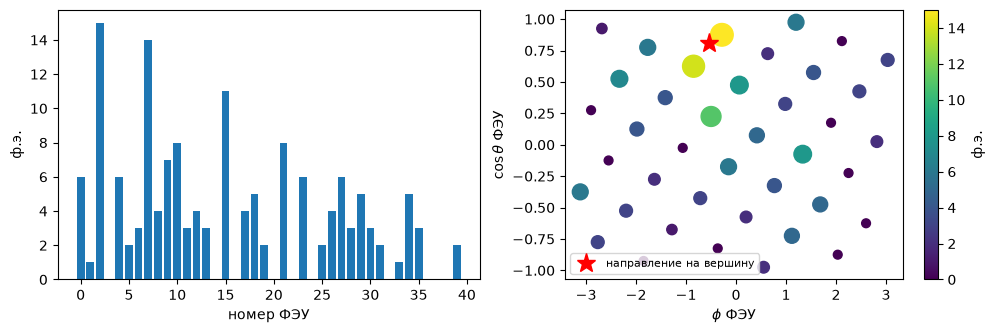

In [2]:
fig = plt.figure(figsize=(12, 3.5))
ax = fig.add_subplot(1, 2, 1)
ax.bar(np.arange(det.N), pe_obs); ax.set_xlabel('номер ФЭУ'); ax.set_ylabel('ф.э.')
ax = fig.add_subplot(1, 2, 2)
th = np.arccos(det.pmt_directions[:, 2]); ph = np.arctan2(det.pmt_directions[:, 1], det.pmt_directions[:, 0])
sc = ax.scatter(ph, np.cos(th), c=pe_obs, s=40 + 15 * pe_obs, cmap='viridis')
ax.plot(np.arctan2(x_true[1], x_true[0]), x_true[2] / np.linalg.norm(x_true), 'r*', ms=14, label='направление на вершину')
ax.set_xlabel(r'$\phi$ ФЭУ'); ax.set_ylabel(r'$\cos\theta$ ФЭУ'); ax.legend(fontsize=8)
plt.colorbar(sc, label='ф.э.'); plt.show()

## Модель и сэмплирование

In [3]:
t = time.perf_counter()
model, idata = reconstruct(det, Y, pe_obs, draws=2000, tune=1000, chains=4, seed=10)
print(f"MAP + NUTS: {time.perf_counter() - t:.0f} с, расхождений: {int(idata.sample_stats.diverging.sum())}")
az.summary(idata, var_names=['E', 'x', 'y', 'z', 'rho'], ci_prob=0.68)

There was 1 divergence after tuning. Increase `target_accept` or reparameterize.


MAP + NUTS: 20 с, расхождений: 1


,mean,sd,eti68_lb,eti68_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
E,1.457,0.149,1.3,1.6,2036,1004,1.00,0.0033,0.0023
x,0.656,0.136,0.52,0.79,1898,1550,1.00,0.0031,0.0019
y,-0.305,0.118,-0.42,-0.19,4057,1615,1.00,0.0019,0.0016
z,0.686,0.133,0.55,0.82,1849,1237,1.00,0.0031,0.0018
rho,1.011,0.147,0.86,1.2,992,521,1.00,0.0048,0.0035


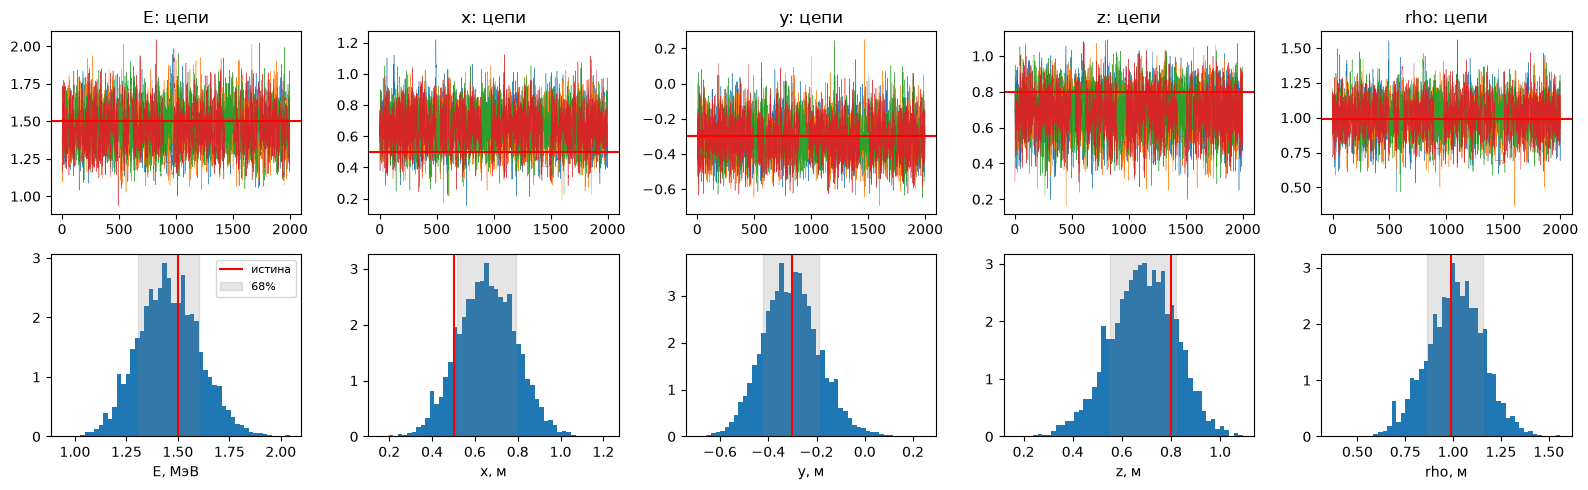

 пар.   истина   среднее ± σ        68% интервал       95% интервал    (среднее-истина)/σ
   E    1.500    1.457 ± 0.149   [ 1.306,  1.604]   [ 1.177,  1.757]   -0.29
   x    0.500    0.656 ± 0.136   [ 0.518,  0.793]   [ 0.399,  0.918]   +1.15
   y   -0.300   -0.305 ± 0.118   [-0.421, -0.189]   [-0.524, -0.063]   -0.04
   z    0.800    0.686 ± 0.133   [ 0.550,  0.820]   [ 0.414,  0.932]   -0.86
 rho    0.990    1.011 ± 0.147   [ 0.864,  1.156]   [ 0.696,  1.301]   +0.14

расстояние от реконструированной вершины до истинной: медиана 27 см


In [4]:
post = {v: idata.posterior[v].values.flatten() for v in ('E', 'x', 'y', 'z', 'rho')}
truth = dict(E=E_true, x=x_true[0], y=x_true[1], z=x_true[2], rho=np.linalg.norm(x_true))
units = dict(E='МэВ', x='м', y='м', z='м', rho='м')

fig, axes = plt.subplots(2, 5, figsize=(16, 5))
for i, v in enumerate(post):
    for chain in idata.posterior[v].values:
        axes[0, i].plot(chain, lw=0.3)
    axes[0, i].axhline(truth[v], color='r'); axes[0, i].set_title(f'{v}: цепи')
    axes[1, i].hist(post[v], bins=50, density=True)
    axes[1, i].axvline(truth[v], color='r', label='истина')
    lo, hi = np.percentile(post[v], [16, 84])
    axes[1, i].axvspan(lo, hi, alpha=0.2, color='gray', label='68%')
    axes[1, i].set_xlabel(f'{v}, {units[v]}')
axes[1, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

print(" пар.   истина   среднее ± σ        68% интервал       95% интервал    (среднее-истина)/σ")
for v in post:
    m_, s_ = post[v].mean(), post[v].std()
    print(f"{v:>4s} {truth[v]:8.3f}  {m_:7.3f} ± {s_:.3f}   [{np.percentile(post[v], 16):6.3f}, {np.percentile(post[v], 84):6.3f}]"
          f"   [{np.percentile(post[v], 2.5):6.3f}, {np.percentile(post[v], 97.5):6.3f}]   {(m_ - truth[v]) / s_:+.2f}")
d = np.sqrt((post['x'] - x_true[0])**2 + (post['y'] - x_true[1])**2 + (post['z'] - x_true[2])**2)
print(f"\nрасстояние от реконструированной вершины до истинной: медиана {np.median(d)*100:.0f} см")

## Корреляции

Энергия и положение коррелированы: из-за затухания один и тот же заряд даёт событие меньшей энергии у стенки (меньше путь, меньше потерь) или большей — в центре.

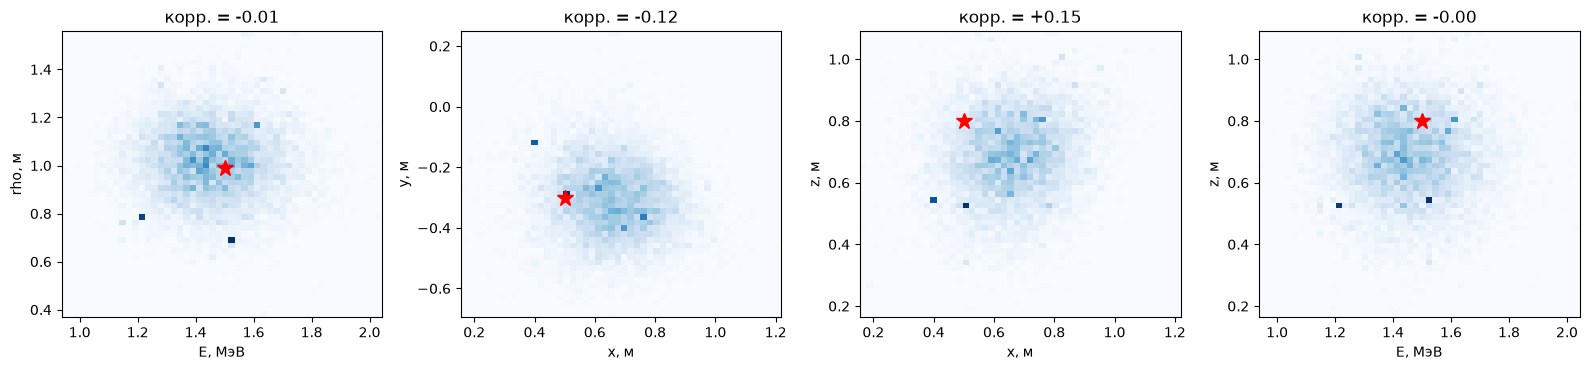

In [5]:
pairs = [('E', 'rho'), ('x', 'y'), ('x', 'z'), ('E', 'z')]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, (a_, b_) in zip(axes, pairs):
    ax.hist2d(post[a_], post[b_], bins=50, cmap='Blues')
    ax.plot(truth[a_], truth[b_], 'r*', ms=12)
    ax.set_xlabel(f'{a_}, {units[a_]}'); ax.set_ylabel(f'{b_}, {units[b_]}')
    ax.set_title(f'корр. = {np.corrcoef(post[a_], post[b_])[0, 1]:+.2f}')
plt.tight_layout(); plt.show()

## Приор и постериор

Сэмплы приора — что известно до измерения: энергия равномерна до 10 МэВ, вершина где угодно в фидуциальном объёме.

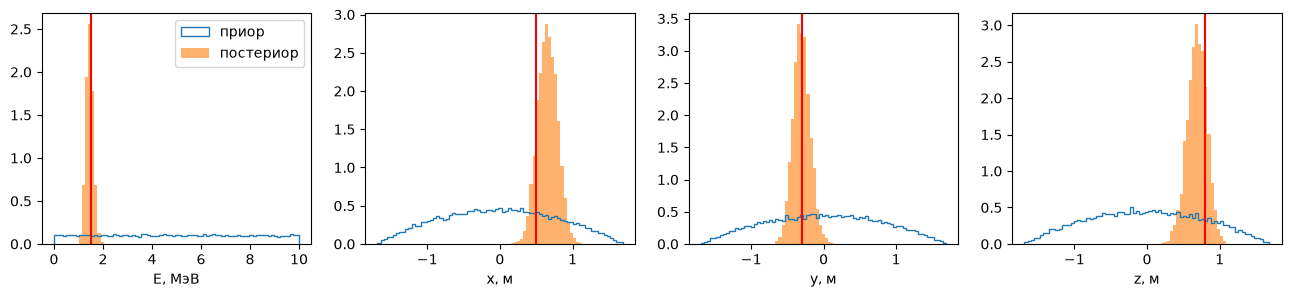

In [6]:
with model:
    prior = pm.sample_prior_predictive(20000, var_names=['E', 'x', 'y', 'z', 'rho'], random_seed=1).prior
prior = {v: prior[v].values.flatten() for v in post}
fig, axes = plt.subplots(1, 4, figsize=(16, 3))
for ax, v in zip(axes, ('E', 'x', 'y', 'z')):
    bins = np.linspace(prior[v].min(), prior[v].max(), 80)
    ax.hist(prior[v], bins=bins, density=True, histtype='step', label='приор')
    ax.hist(post[v], bins=bins, density=True, alpha=0.6, label='постериор')
    ax.axvline(truth[v], color='r'); ax.set_xlabel(f'{v}, {units[v]}')
axes[0].legend(); plt.show()

## Точное правдоподобие против пуассоновского приближения

Если считать $\mathrm{pe}_k \sim \mathrm{Poisson}(a\lambda_k)$, теряются флуктуации числа ф.э. на фотон: дисперсия заряда $a\lambda$ вместо $a\lambda(1+a)$. Постериор от этого становится уже, чем допускают данные.

In [7]:
_, idata_p = reconstruct(det, Y, pe_obs, draws=2000, tune=1000, chains=4, seed=11, likelihood='poisson')
post_p = {v: idata_p.posterior[v].values.flatten() for v in post}
print(" пар.   Нейман A: среднее ± σ    Пуассон: среднее ± σ    σ_Пуассон / σ_Нейман")
for v in ('E', 'x', 'y', 'z'):
    print(f"{v:>4s}   {post[v].mean():7.3f} ± {post[v].std():.3f}       {post_p[v].mean():7.3f} ± {post_p[v].std():.3f}"
          f"        {post_p[v].std() / post[v].std():.2f}")
print(f"ожидаемое отношение 1/sqrt(1+a) = {1/np.sqrt(1 + det.a):.2f}")

 пар.   Нейман A: среднее ± σ    Пуассон: среднее ± σ    σ_Пуассон / σ_Нейман
   E     1.457 ± 0.149         1.497 ± 0.123        0.82
   x     0.656 ± 0.136         0.635 ± 0.109        0.80
   y    -0.305 ± 0.118        -0.294 ± 0.095        0.81
   z     0.686 ± 0.133         0.672 ± 0.104        0.78
ожидаемое отношение 1/sqrt(1+a) = 0.82


## Проверка на серии событий

Один постериор ничего не говорит о смещении и о правильности ширины. Восстановим 40 событий с $E = 1.5$ МэВ в случайных точках внутри шара радиуса 1.5 м и посмотрим на «пуллы» $(\langle\theta\rangle - \theta_{true})/\sigma_\theta$: при несмещённой реконструкции с правильной оценкой ошибок они распределены как $\mathcal N(0, 1)$, а истинное значение попадает в 68%-интервал в ~68% случаев.

40 реконструкций: 633 с
сходимость: max r_hat = 1.055, событий с r_hat > 1.05: 2;  расхождений на событие (1000 сэмплов): медиана 0, максимум 8
E: пулл = +0.01 ± 0.97,  истина в 68%-интервале: 62%,  в 95%: 98%
x: пулл = +0.01 ± 0.87,  истина в 68%-интервале: 72%,  в 95%: 100%
y: пулл = -0.06 ± 0.88,  истина в 68%-интервале: 82%,  в 95%: 95%
z: пулл = -0.10 ± 1.08,  истина в 68%-интервале: 55%,  в 95%: 95%


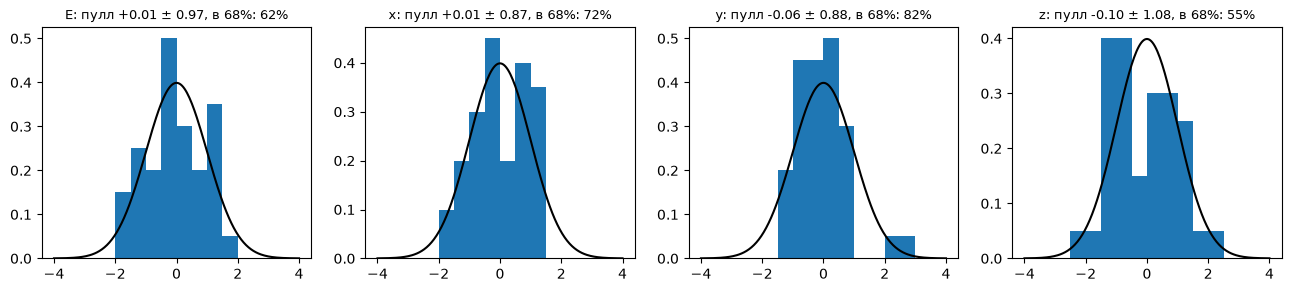

энергия: среднее восстановленное 1.510 МэВ (истина 1.5), σ_E/E = 10.2% (медиана);  разброс оценок 9.9%
вершина: σ по координате ≈ 11 см (медиана)
ожидаемое разрешение по заряду sqrt((1+a)/<Q>) = 10.1%


In [8]:
rng = np.random.default_rng(100)
n_ev = 40
rows, rhat_max, n_div = [], [], []
t = time.perf_counter()
for i in range(n_ev):
    v = rng.normal(size=3); v /= np.linalg.norm(v)
    xt = v * 1.5 * rng.uniform() ** (1 / 3)
    pe = det.response(xt, Source(Y=Y, rng=1000 + i).directions(E_true))
    _, idt = reconstruct(det, Y, pe, draws=500, tune=500, chains=2, seed=i, compute_convergence_checks=False)
    tr = idt.posterior
    rh = az.rhat(idt, var_names=['E', 'x', 'y', 'z']); rhat_max.append(max(float(rh[k]) for k in 'Exyz'))
    n_div.append(int(idt.sample_stats.diverging.sum()))
    s = {k: tr[k].values.flatten() for k in 'Exyz'}
    tv = dict(E=E_true, x=xt[0], y=xt[1], z=xt[2])
    rows.append({k: (s[k].mean(), s[k].std(), tv[k],
                     np.percentile(s[k], 16) <= tv[k] <= np.percentile(s[k], 84)) for k in 'Exyz'})
print(f"{n_ev} реконструкций: {time.perf_counter() - t:.0f} с")
print(f"сходимость: max r_hat = {max(rhat_max):.3f}, событий с r_hat > 1.05: {sum(r > 1.05 for r in rhat_max)};"
      f"  расхождений на событие (1000 сэмплов): медиана {np.median(n_div):.0f}, максимум {max(n_div)}")

fig, axes = plt.subplots(1, 4, figsize=(16, 3))
g = np.linspace(-4, 4, 200)
for ax, k in zip(axes, 'Exyz'):
    pulls = np.array([(r[k][0] - r[k][2]) / r[k][1] for r in rows])
    cover = np.mean([r[k][3] for r in rows])
    ax.hist(pulls, bins=np.linspace(-4, 4, 17), density=True)
    ax.plot(g, np.exp(-g**2 / 2) / np.sqrt(2 * np.pi), 'k')
    ax.set_title(f'{k}: пулл {pulls.mean():+.2f} ± {pulls.std():.2f}, в 68%: {cover:.0%}', fontsize=9)
    print(f"{k}: пулл = {pulls.mean():+.2f} ± {pulls.std():.2f},  истина в 68%-интервале: {cover:.0%},  в 95%: {np.mean(np.abs(pulls) < 1.96):.0%}")
plt.show()

sig_E = np.array([r['E'][1] for r in rows]); mean_E = np.array([r['E'][0] for r in rows])
sig_pos = np.array([np.sqrt(r['x'][1]**2 + r['y'][1]**2 + r['z'][1]**2) / np.sqrt(3) for r in rows])
print(f"энергия: среднее восстановленное {mean_E.mean():.3f} МэВ (истина {E_true}), "
      f"σ_E/E = {np.median(sig_E) / E_true:.1%} (медиана);  разброс оценок {mean_E.std() / E_true:.1%}")
print(f"вершина: σ по координате ≈ {np.median(sig_pos) * 100:.0f} см (медиана)")
print(f"ожидаемое разрешение по заряду sqrt((1+a)/<Q>) = {np.sqrt((1 + det.a) / pe_obs.sum()):.1%}")

**Выводы.**
- **Одно событие** ($E = 1.5$ МэВ, $\vec x = (0.5, -0.3, 0.8)$ м, $Q = 148$ ф.э.): $E = 1.46 \pm 0.15$ МэВ, $\vec x = (0.66, -0.31, 0.69) \pm 0.13$ м. Все параметры в пределах $1.2\sigma$ от истины, вершина восстановлена с точностью ~27 см. Сходимость хорошая: $\hat r = 1.00$, эффективный размер выборки ~2000, одно расхождение на 8000 сэмплов.
- **Серия из 40 событий:** средняя восстановленная энергия $1.510$ МэВ при истинной 1.5 — смещения нет. Пуллы $E, x, y, z$: среднее $|{\le}0.1|$, ширина 0.87–1.08 ≈ 1; истина попадает в 68%-интервал в 55–82% случаев (ожидание 68%, статистическая погрешность при 40 событиях ±7%), в 95%-интервал — в 95–100%. То есть постериор правильно оценивает и само значение, и его неопределённость.
- **Разрешение:** $\sigma_E/E \approx 10\%$ при 1.5 МэВ — совпадает с пределом $\sqrt{(1+a)/\langle Q\rangle} = 10.1\%$, задаваемым статистикой фотоэлектронов (задача 4). Неизвестное положение вершины разрешение почти не ухудшает: 40 каналов несут достаточно информации, чтобы определить вершину с точностью ~11 см по каждой координате.
- **Правдоподобие важно:** пуассоновское приближение $\mathrm{pe}_k \sim \mathrm{Poisson}(a\lambda_k)$ сужает постериор в $0.8 \approx 1/\sqrt{1+a}$ раза, т.е. ошибки получились бы заниженными на 20%. Точное распределение Неймана типа A учитывает флуктуации числа ф.э. на фотон.
- **Практические уроки MCMC:** (1) приор без разрывов (параметризация шара через $\mathrm{Beta}(3,1)$ вместо отсечения), (2) старт цепей из MAP — иначе цепи застревают в побочных максимумах у стенки, что давало смещение энергии на +10% и $\hat r$ до 1.8, (3) фидуциальный объём $0.85R$, где модель правдоподобия надёжна. Без этих мер реконструкция выглядела бы правдоподобно на отдельном событии, но была бы смещена на серии — поэтому её обязательно проверять по пуллам.